## to do:

QoL
- plot nodes at any level of transform, see all_nodes
- automatically perform max. level transform
- plot single node by path
- time [s] instead of coefficient number
- automatically perform nodes2data on inverse
- fix plots

visualisation:
- graph neural network (python package)
- add scientific form to heisenberg plot
- add automatic ticks formatting to heisenberg plot?

studentship:
- sensitivity analysis
- testing/tuning thresholding values (classification without machine learning)
- validate kurtosis and crest factor
- test border effects on kurtosis and crest factor
- test with data length of power of 2
- develop classifier
- clustering (e.g. k-means) using energy, kurtosis, crest factor is input features.
- 8 pages for manuscript
- normalise clustering
- look at effect of number of clusters
- learn about k-means and how it's used (reaserch)
- look at how it's used with dwpt
- explain and justify procedure for classification using research
- ksvd, knn
- settle on a method by next meeting
- number of clusters
- break down notebook
- measuring effectiveness of k-means
- rename notebooks
- read about theory
- implement neural networks
- learn about k-means
- write manuscript: add literature review
- random forest
- and other machine learning algorithms that sound fun
- look at to fix in k-means file
- write statistical_feature_calculation.py file
- implement simple neural network (do reserach, learn about other peoples' solutions)
- neural networks k-means
- reserach other machine learning methods

- check sum of reconstructed nodes is the same as reconstructing them both at once.
- use k-means + soft k-means for classification.
- use pandas dataframe for notebooks
- use pd dataframe for wavelet transform object as well

- check out tree diagram
- add functionality to base node
- mess around with statistical measures used in training data
- change number of clusters.
- hyperparameter tuning
- ensure reproducibility
- upload references

Reza
- bubble dynamics

# Decompose a signal to its components at different frequency bands with WPT

In this notebook we aim to test WPT for extracting different components of a signal based on the energy, kurtosis, and crest factor of different frequency bands. The WPT library requires python3.6+ version. The following cell checks this requirement.

In [19]:
import sys

if sys.version_info[0] + 0.1 * sys.version_info[1] < 3.6:
    raise Exception("Must be using Python 3.6+ version")

Import the wavelet_transform package and required libraries.

In [20]:
sys.path.append("..")
from wavelet_transform.wpt import transform as wpt
from wavelet_transform.test import synthetic_data as sd
from wavelet_transform.wpt import inverse_transform as inv
from wavelet_transform.postprocess import plotting as plot

# matplotlib.use('nbagg')
import matplotlib.pyplot as plt
import numpy as np
import pywt
import scipy.stats as sc

Specify the parameters for generating a synthetic signal and to perform wavelet packet transform.

In [21]:
# keep the same
sampling_rate = 100  # unit: Hz

# PARAMETERS TO CHANGE
amplitudes = [1, 0.8, 0.4]  # amplitude of each sine wave
frequencies = [5, 15, 25]  # frequency content of signal
phases = [0, np.deg2rad(45), np.deg2rad(120)]  # phase of each sine wave

duration = 1000 / min(frequencies)  # duration of wave

trans_amp = [10 for _ in range(5)]  # amplitudes of transients
n_trans = len(trans_amp)  # number of transients
trans_dur = [0.05 for _ in range(n_trans)]  # duration of transients
trans_time = [
    duration * i / (n_trans + 1) for i in range(1, n_trans + 1)
]  # times of transients

std_noise = 0.1

wavelet = "db6"
levels = 5
mode = "symmetric"

sort_by = 'energy'  # 'energy', 'kurtosis', 'crest', 'False' -> freq
sort = "rec"  # 'rec' (reconstructed signal) 'coef' (transform coefficients)
n_highest = 3

fft_lim = 50  # increase value to view more of the fft plots

Generate synthetic multitonal signal with/without additive noise. We will fft the signal to double check the frequency contents.

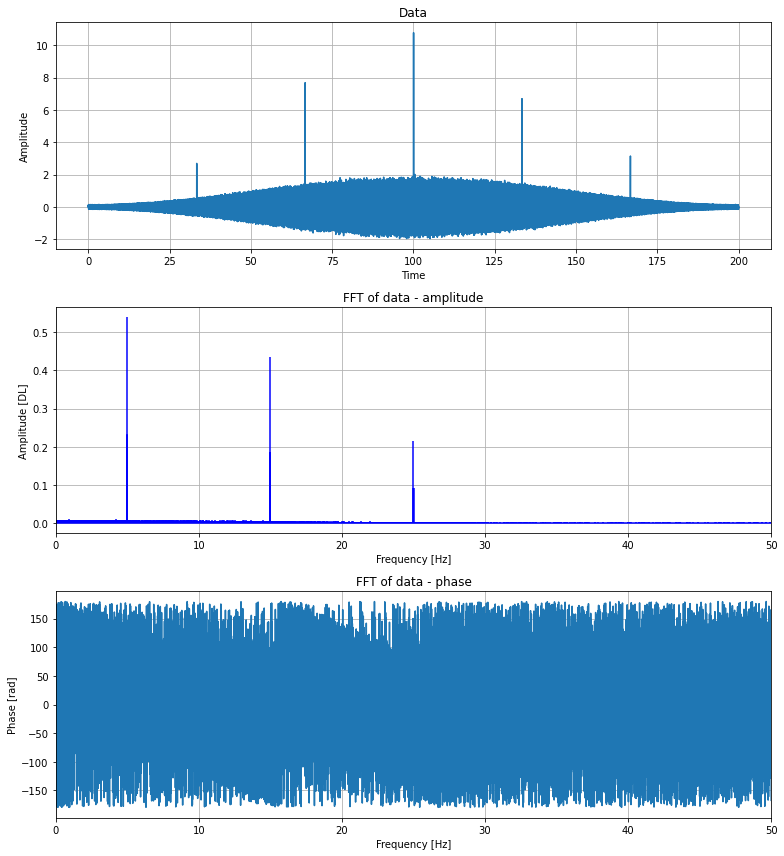

In [22]:
# generate sound wave
data, t_plot = sd.sound_wave(amplitudes, frequencies, phases, duration, sampling_rate)
signal_length = len(data)
data += sd.transients(trans_amp, trans_time, trans_dur, duration, sampling_rate)
data += sd.noise(std_noise,duration,sampling_rate)
data *= np.hamming(signal_length)

fft_data = np.fft.fft(data)[0 : int(signal_length / 2)] / (
    signal_length / 2
)  # division by signal_length/2 is to correct the amplitude (energy) in the freq domain
freq = np.fft.fftfreq(signal_length, d=1 / sampling_rate)[0 : int(signal_length / 2)]

# plot sound wave and fft
fig, ax = plt.subplots(3, figsize=(11, 12))
ax[0].plot(t_plot, data)
ax[0].set_title("Data")
ax[0].set_xlabel("Time")
ax[0].set_ylabel("Amplitude")
ax[0].grid()

ax[1].stem(
    freq,
    np.abs(fft_data),
    linefmt="b",
    markerfmt=" ",
    basefmt="-b",
    use_line_collection=True,
)
ax[1].set_title("FFT of data - amplitude")
ax[1].set_xlabel("Frequency [Hz]")
ax[1].set_ylabel("Amplitude [DL]")
ax[1].set_xlim(0, sampling_rate / 2)
ax[1].grid()

ax[2].plot(freq, np.angle(fft_data, deg=True))
ax[2].set_title("FFT of data - phase")
ax[2].set_xlabel("Frequency [Hz]")
ax[2].set_ylabel("Phase [rad]")
ax[2].set_xlim(0, sampling_rate / 2)
ax[2].grid()
fig.tight_layout()
plt.show()

### Frequency content of reconstructed subbands
Decompose signal using discrete wavelet packet transform and sort the nodes in order of energy, kurtosis, or crest factor.

functions used for sorting

In [23]:
def calc_crest_factor(array):
    rms = np.sqrt(1 / len(array) * sum(array**2))
    return 10 * np.log10(max(array**2) / rms)


def calc_energy(array):
    return 1 / len(array) * sum(array**2)


def sort_nodes(rec, sort="rec", sort_by="energy"):
    """
    choose how to sort the subbands

    Parameters
    ----------
    rec: tuple
        tuple containing (coefficients,reconstructed_wave,fft_of_rec_wave,energy,kurtosis,crest)
    sort: str
        sort by 'energy', 'kurtosis', or 'crest' factor
    coef_or_rec: str
        sort by calculating attributes of the node coefficients or the reconstructed wave

    returns
    -------
    rec: tuple
        sorted input
    """
    if sort == "rec":
        if sort_by == "energy": 
            return sorted(rec, key=lambda x: x[3], reverse=True)
        elif sort_by == "kurtosis":
            return sorted(rec, key=lambda x: x[4], reverse=True)
        elif sort_by == "crest":
            return sorted(rec, key=lambda x: x[4], reverse=True)
            


    elif sort == "coef":
        if sort_by == "energy":
            return sorted(rec, key=lambda x: x[0].energy, reverse=True)
        if sort_by == "kurtosis":
            return sorted(rec, key=lambda x: x[0].kurtosis, reverse=True)
        if sort_by == "crest":
            return sorted(rec, key=lambda x: x[0].crest_factor, reverse=True)

Transform and sort nodes

In [24]:
# WPT transform
tr_ob = wpt.dwpt(data, levels, wavelet, mode)
tr_ob.calc_frequencies(sampling_rate)

# reconstruct each node separately
rec = []

for node in tr_ob.get_level(order="freq"):
    inverse = inv.inv_dwpt(tr_ob, nodes=node)
    inverse_signal_length = len(inverse)
    fft = np.fft.fft(inverse)[0 : int(inverse_signal_length / 2)] / (
        inverse_signal_length * 0.5
    )
    energy = calc_energy(inverse)
    kurtosis = sc.kurtosis(inverse)
    crest = calc_crest_factor(inverse)
    rec.append((node, inverse, fft, energy, kurtosis, crest))

plot the **`n_highest`** energy components (subbands).

In [25]:
def plot_reconstructions(rec, n_highest=None, group=None):
    partial_rec = np.zeros(signal_length)  # track sum of highest energy subbands
    if n_highest is None:
        n_highest = len(rec)
    for i, rec in enumerate(rec[:n_highest]):  # highest energy, kurtosis, etc.
        node, rec_wave, fft, *_ = rec
        partial_rec += rec_wave  # full reconstruction
        fig, ax = plt.subplots(
            2, figsize=(11, 8)
        )  # plot reconstructed wave and its fft
        freq_r = node.frequency_range
        ax[0].plot(t_plot, rec_wave)
        title = f"Reconstructed subband [{freq_r[0]}- {freq_r[1]} Hz]"
        if group is not None:
            title = f"Reconstructed subband [{freq_r[0]}- {freq_r[1]} Hz] group: {group[i]}"
        ax[0].set_title(title)
        ax[0].set_xlabel("time")
        ax[0].set_ylabel("amplitude")
        ax[1].stem(
            freq,
            np.abs(fft),
            linefmt="b",
            markerfmt=" ",
            basefmt="-b",
            use_line_collection=True,
        )
        ax[1].set_title("FFT of reconstructed subband")
        ax[1].set_xlabel("Frequency")
        ax[1].set_ylabel("Power")
        ax[1].set_xlim(
            max(0, freq_r[0] - fft_lim), min(sampling_rate / 2, freq_r[1] + fft_lim)
        )
        ax[1].grid()
        fig.tight_layout()
        plt.show()

        # print info
        print(f"energy of recovered signal: {calc_energy(rec_wave)}")
        print(f"kurtosis of recovered signal: {sc.kurtosis(rec_wave)}")
        print(f"crest factor of recovered signal: {calc_crest_factor(rec_wave)}")
        print()
        print(f"energy of node coefficients: {node.energy}")
        print(f"kurtosis of node coefficients: {node.kurtosis}")
        print(f"crest factor of node coefficients: {node.crest_factor}")
    return partial_rec

run = False
if run is True:
    # sort reconstructed waves
    sorted_rec = sort_nodes(rec, sort, sort_by)
    print(f"sorted by: {sort_by} of {sort}")
    # plot highest energy subbands
    partial_rec = plot_reconstructions(sorted_rec,n_highest)

### heisenberg visualisation

Making an heisenberg plot of the last level of dwpt

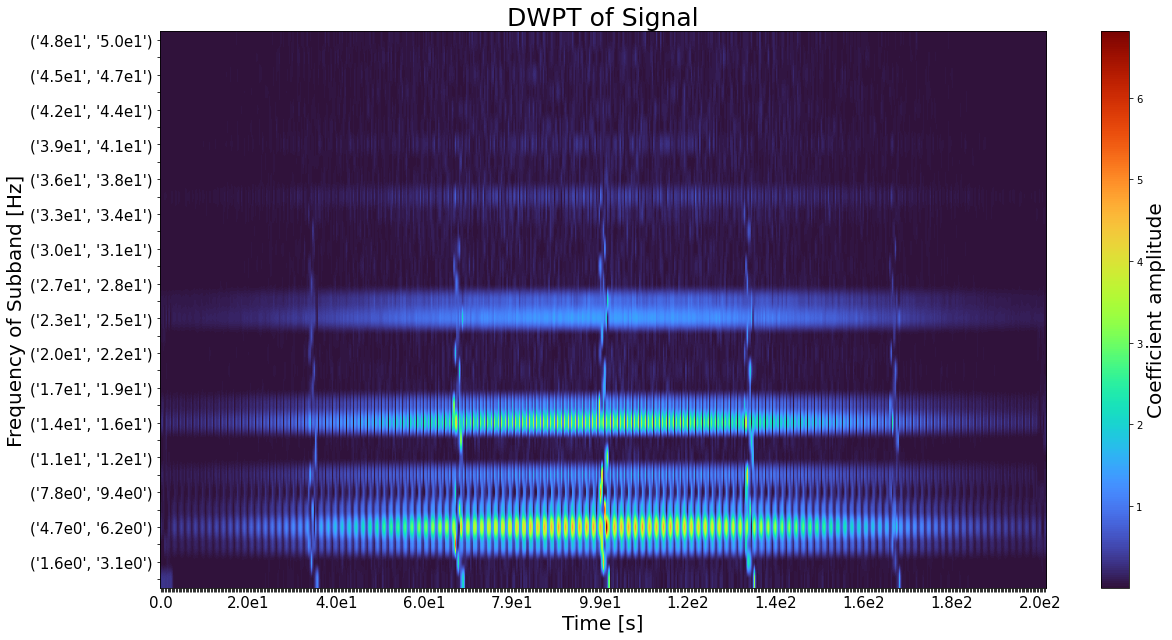

In [26]:
plot.heisenberg(tr_ob, max(t_plot))

### Clustering

k-means clustering algorithm with energy, kurtosis, and crest factor as the input

In [27]:
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
import numpy as np

# training data
data_train = []
for _,inverse,_,energy,kurtosis,crest in rec:
    data_train.append(
        (energy, kurtosis, crest)# max(abs(inverse)), 
         #np.mean(inverse), sc.skew(inverse))
        )

scaler = StandardScaler()
data_train_normalised = scaler.fit_transform(data_train)

# training k-means algorithm
no_clusters = 5
kmeans = KMeans(n_clusters=no_clusters)
kmeans.fit(data_train_normalised)

# get labels and clusters
labels = kmeans.labels_
centers = scaler.inverse_transform(kmeans.cluster_centers_)

### Reassigning Groups

Post-hoc reassignment of groups based on the energy and kurtosis of their clusters.

In [28]:
def assign_labels(centers, labels, sort_by=1):
    """
    assign labels to clusters. Assign the highest cluster number to the centre with 
    highest energy. Then assign the rest in order of sort_by. The group numbers are reassigned
    to 1-indexed groups.

    Paramaters
    -----------
    centers: array
        array where each row is a centre of a cluster
    labels: list
        list of group assignments to reassign
    sort_by: int
        always sort out the highest energy because the harmonic can be separated
        from the rest by its much greater energy. Otherwise, sort by attribute
        number = sort_by of the centres.
    """
    # sort labels by energy, highest cluster energy is highest group number
    sort_by_energy = np.argsort(centers[:, 0])

    # sort rest of the labels by kurtosis
    sort_rest = np.argsort(centers[:, sort_by])

    sort_rest = np.delete(
        sort_rest, # delete highest energy group form kurtosis
        np.where(sort_rest == sort_by_energy[-1])[0][0], 
        axis=0
        )
    sort_rest = np.append(sort_rest, None)

    # create mapping from old cluster labels to new cluster labels
    mapping = {}
    for new_label, index in enumerate(zip(sort_by_energy, sort_rest)):
        if new_label == len(sort_by_energy) - 1:  # highest group no has highest energy
            mapping[index[0]] = new_label + 1
        else:
            mapping[index[1]] = new_label + 1  # other group numbers are arranged by kurtosis

    # update labels
    reassigned_labels = [mapping[label] for label in labels]
    return reassigned_labels

In [29]:
reassigned_labels = assign_labels(centers, labels)

### plot result

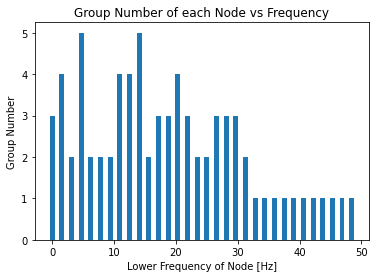

Cluster labels: [3, 4, 2, 5, 2, 2, 2, 4, 4, 5, 2, 3, 3, 4, 3, 2, 2, 3, 3, 3, 2, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1]
highest energy: 3
highest kurtosis: 1
highest crest factor: 1


In [30]:
# plot regular k-means
plt.bar([node.frequency_range[0] for node,*_ in rec], reassigned_labels)
plt.title('Group Number of each Node vs Frequency')
plt.xlabel('Lower Frequency of Node [Hz]')
plt.ylabel('Group Number')
plt.show()

print("Cluster labels:", reassigned_labels)
print(f"highest energy: {np.argmax(centers[:,0])}")
print(f'highest kurtosis: {np.argmax(centers[:,1])}')
print(f'highest crest factor: {np.argmax(centers[:,2])}')

### PCA

In [31]:
# apply PCA to training data
pca = PCA(n_components=3)
data_pca = pca.fit_transform(data_train_normalised)

# training k-means algorithm on the reduced data
kmeans_pca = KMeans(n_clusters=no_clusters)
kmeans_pca.fit(data_pca)

labels_pca = kmeans_pca.labels_
centers_pca = scaler.inverse_transform(pca.inverse_transform(kmeans_pca.cluster_centers_))
reassigned_pca_labels = assign_labels(centers_pca, labels_pca)

### Plot PCA Result

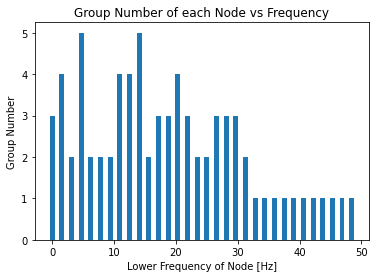

Eigenvectors:
Energy, Kurtosis, Crest factor, Peak, Mean
[[-0.13  0.72  0.68]
 [ 0.92 -0.16  0.35]
 [-0.36 -0.67  0.64]]
Eigenvalues: [1.71 1.14 0.25]
Cluster labels: [4 1 2 3 2 2 2 1 1 3 2 4 4 1 4 2 2 4 4 4 2 0 0 0 0 0 0 0 0 0 0 0]
highest PC1: 3
highest PC2: 1
highest PC3: 1


In [32]:
# plot pca k-means
lower_freqs = [node.frequency_range[0] for node,*_ in rec]
plt.bar([node.frequency_range[0] for node,*_ in rec], reassigned_pca_labels)
plt.tick_params
plt.title('Group Number of each Node vs Frequency')
plt.xlabel('Lower Frequency of Node [Hz]')
plt.ylabel('Group Number')
plt.show()

eigenvectors = pca.components_
eigenvalues = pca.explained_variance_

print("Eigenvectors:")
print('Energy, Kurtosis, Crest factor, Peak, Mean')
print(np.round(eigenvectors,2))

print("Eigenvalues:", np.round(eigenvalues,2))

print("Cluster labels:", labels_pca)
print(f"highest PC1: {np.argmax(centers_pca[:,0])}")
print(f'highest PC2: {np.argmax(centers_pca[:,1])}')
print(f'highest PC3: {np.argmax(centers_pca[:,2])}')

### 3d plot

3d plots of the results with axes energy, kurtosis, crest factor

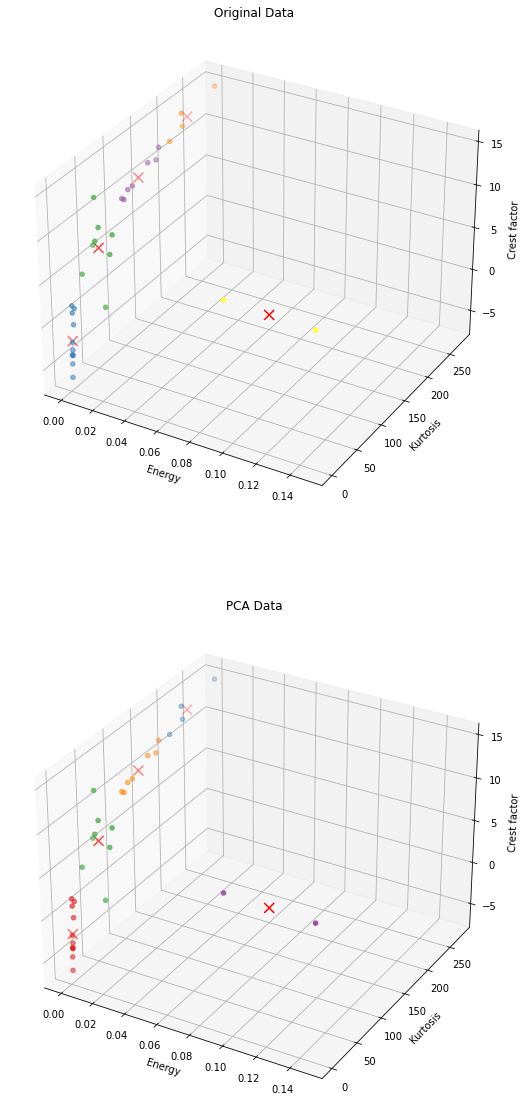

In [33]:
fig, ax = plt.subplots(2, figsize=(20, 20), subplot_kw={'projection': '3d'})

titles = ['Original Data', 'PCA Data']

# plot subplots for PCA data and non-PCA data
for i, ax in enumerate(ax):
    cmap = plt.cm.get_cmap('Set1')
    if i == 0:
        data_scatter = data_train
        centers_scatter = centers
        labels_scatter = reassigned_labels
    else:
        data_scatter = data_train
        centers_scatter = centers_pca
        labels_scatter = labels_pca

    ax.scatter(
        [point[0] for point in data_scatter],
        [point[1] for point in data_scatter],
        [point[2] for point in data_scatter],
        c=[cmap(label) for label in labels_scatter])
    ax.scatter(
        centers_scatter[:, 0],
        centers_scatter[:, 1],
        centers_scatter[:, 2],
        c='red', marker='x', s=100)
    
    ax.set_xlabel('Energy')
    ax.set_ylabel('Kurtosis')
    ax.set_zlabel('Crest factor')
    ax.set_title(titles[i])

plt.show()

### 2d plot

plots with energy vs crest factor comparing PCA and no PCA results

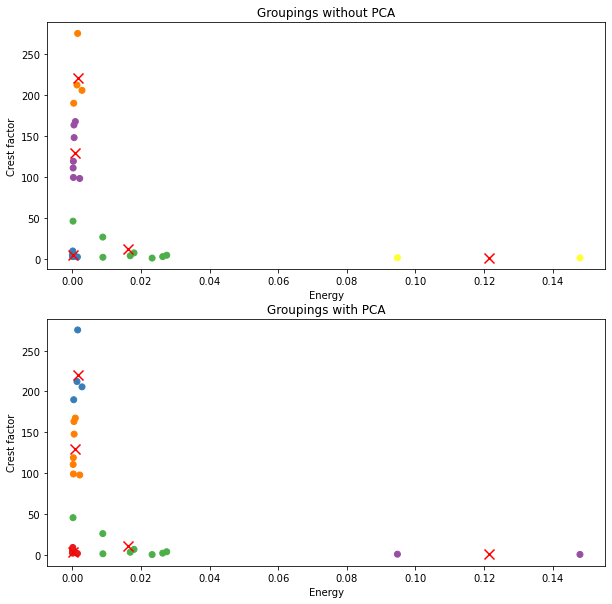

In [34]:
# 3d plot
fig, ax = plt.subplots(2,figsize=(10,10))

# plot with colours for each cluster
cmap = plt.cm.get_cmap('Set1')
x = 0  # 0 -> energy, 1 -> kurtosis, 3 -> crest
y = 1  # ""
data_scatter = data_train
labels_scatter = reassigned_labels
ax[0].scatter(
    [point[x] for point in data_scatter],
    [point[y] for point in data_scatter],
    c=[cmap(label) for label in labels_scatter]
)
labels_scatter = labels_pca
ax[1].scatter(
    [point[x] for point in data_scatter],
    [point[y] for point in data_scatter],
    c=[cmap(label) for label in labels_scatter]
)
# plot centres
centers_scatter = centers
ax[0].scatter(centers_scatter[:, x], 
           centers_scatter[:, y], c='red', marker='x', s=100)
centers_scatter = centers_pca
ax[1].scatter(centers_scatter[:, x], 
           centers_scatter[:, y], c='red', marker='x', s=100)
for i in range(2):
    ax[i].set_xlabel('Energy')
    ax[i].set_ylabel('Crest factor')
ax[0].set_title('Groupings without PCA')
ax[1].set_title('Groupings with PCA')
plt.show()

### Results

Plotting the reconstructed waves from clustering with their assigned group

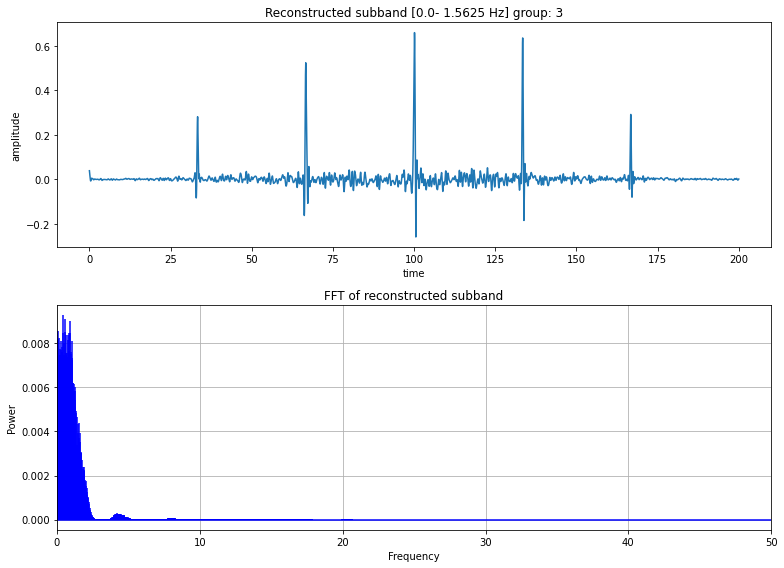

energy of recovered signal: 0.002158620232143051
kurtosis of recovered signal: 98.00946152926531
crest factor of recovered signal: 9.7167333813432

energy of node coefficients: 0.06872978590971333
kurtosis of node coefficients: 118.94745703605658
crest factor of node coefficients: 9.149856885966518


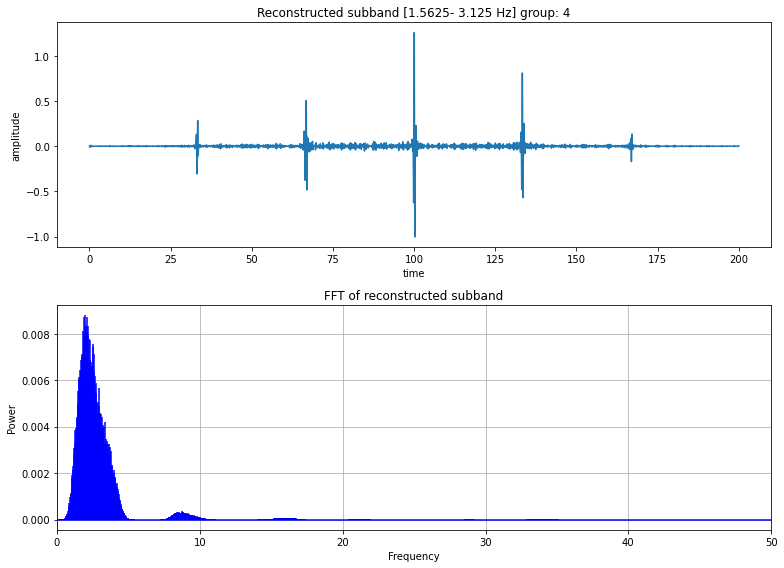

energy of recovered signal: 0.0028264163218766755
kurtosis of recovered signal: 205.6673269024024
crest factor of recovered signal: 14.727624917523624

energy of node coefficients: 0.08878435224068912
kurtosis of node coefficients: 116.23806226449399
crest factor of node coefficients: 9.762049540381664


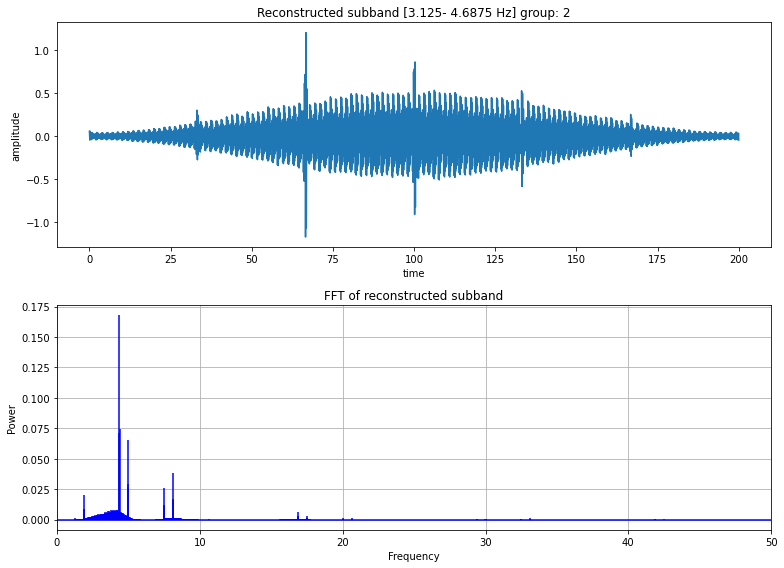

energy of recovered signal: 0.026336148541037774
kurtosis of recovered signal: 2.562934477076711
crest factor of recovered signal: 9.480151681962303

energy of node coefficients: 0.8297312154349828
kurtosis of node coefficients: 4.890318855595377
crest factor of node coefficients: 1.389419251122471


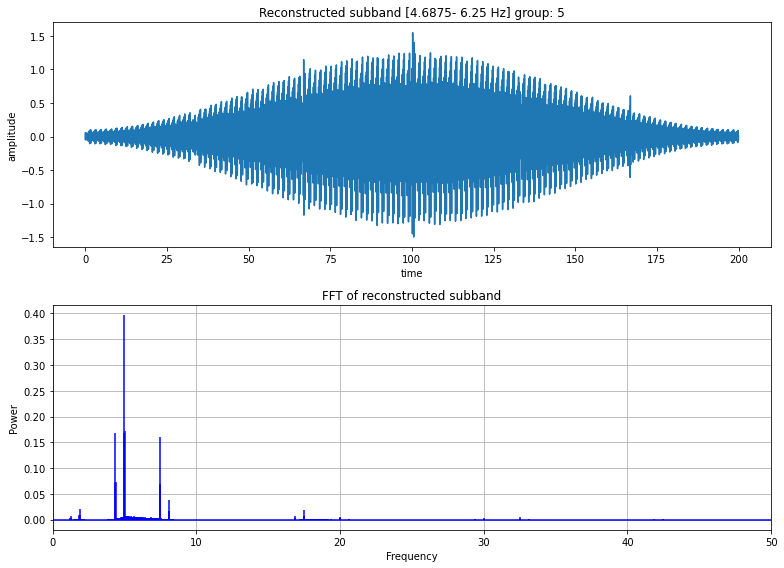

energy of recovered signal: 0.14792518068660948
kurtosis of recovered signal: 0.9539192802789227
crest factor of recovered signal: 7.951574484690279

energy of node coefficients: 4.65949548549174
kurtosis of node coefficients: 2.8839009584393844
crest factor of node coefficients: -4.030071981430665


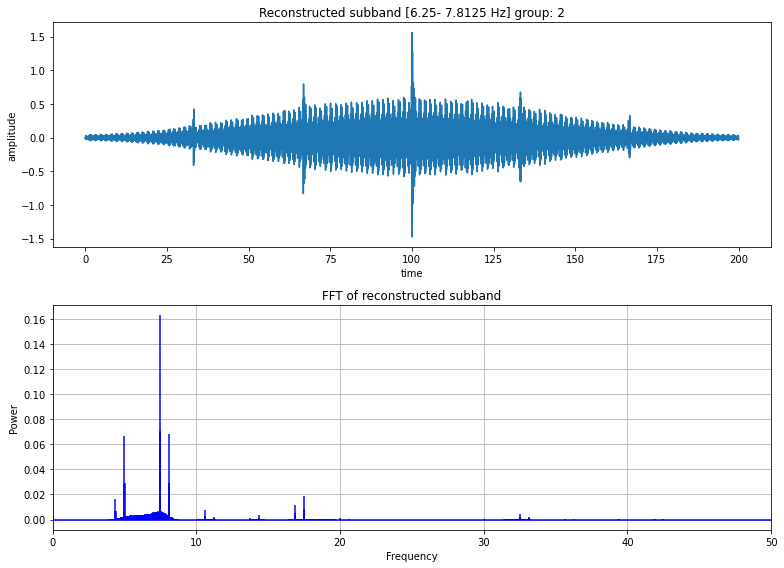

energy of recovered signal: 0.02751220332901714
kurtosis of recovered signal: 4.264772769860192
crest factor of recovered signal: 11.659585811215912

energy of node coefficients: 0.8665931245495841
kurtosis of node coefficients: 6.64702712714525
crest factor of node coefficients: 2.9957206162544674


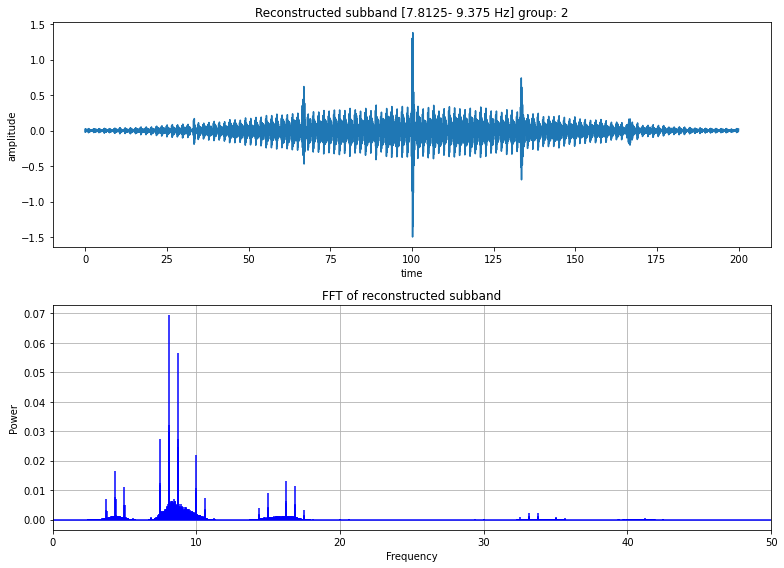

energy of recovered signal: 0.008880943611566265
kurtosis of recovered signal: 26.41923199900472
crest factor of recovered signal: 13.77577013433738

energy of node coefficients: 0.2797784232794536
kurtosis of node coefficients: 19.41476812879089
crest factor of node coefficients: 5.862541197796107


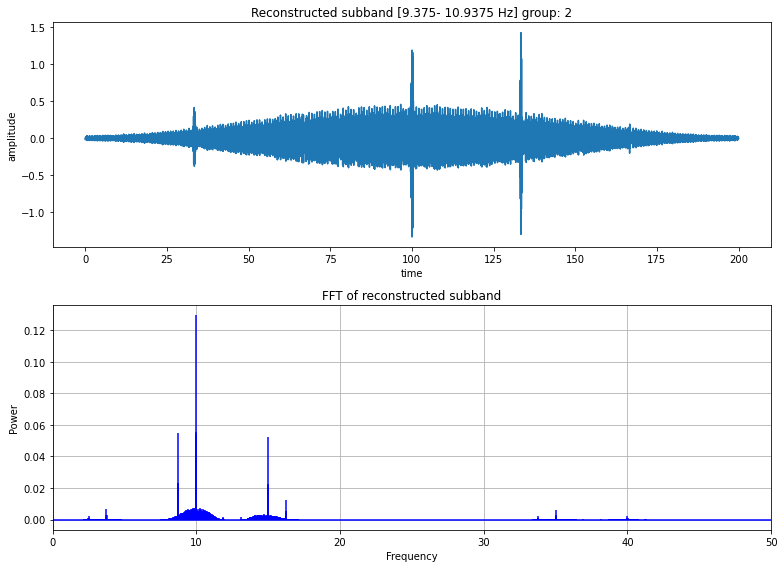

energy of recovered signal: 0.017978602754198186
kurtosis of recovered signal: 7.120634593423073
crest factor of recovered signal: 11.835326391003774

energy of node coefficients: 0.5663229278402748
kurtosis of node coefficients: 7.983477853103976
crest factor of node coefficients: 3.0579177045764045


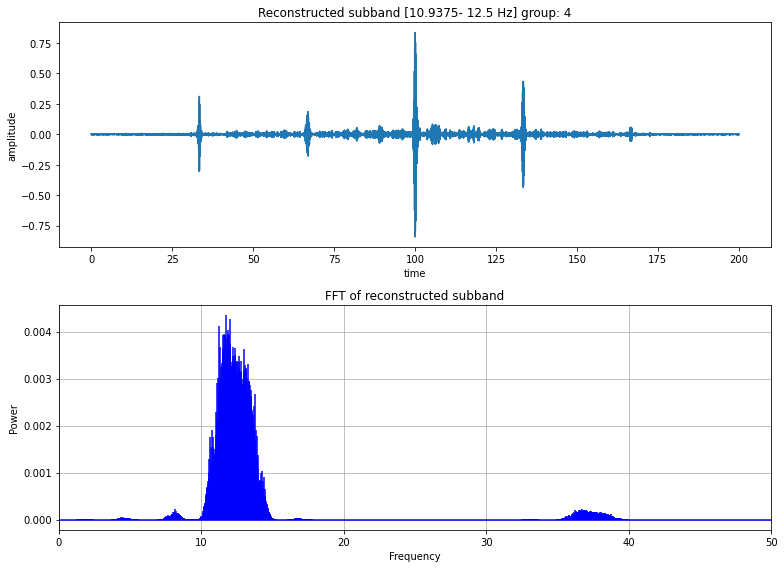

energy of recovered signal: 0.0013592082665343326
kurtosis of recovered signal: 212.1863563808487
crest factor of recovered signal: 12.849197205381124

energy of node coefficients: 0.04279960402276603
kurtosis of node coefficients: 156.5335355855619
crest factor of node coefficients: 10.34869676576668


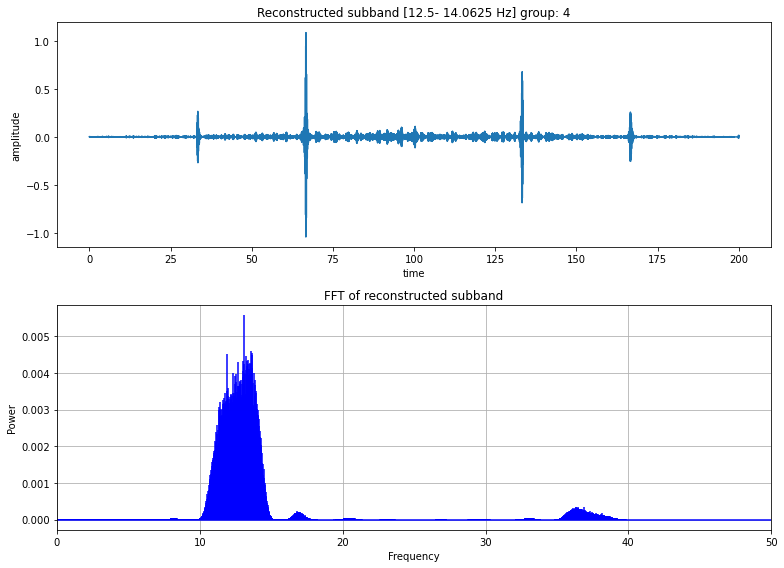

energy of recovered signal: 0.0015554989435015135
kurtosis of recovered signal: 275.18539838950886
crest factor of recovered signal: 14.74295364937735

energy of node coefficients: 0.04904013423596297
kurtosis of node coefficients: 167.3093760983453
crest factor of node coefficients: 10.842899055987832


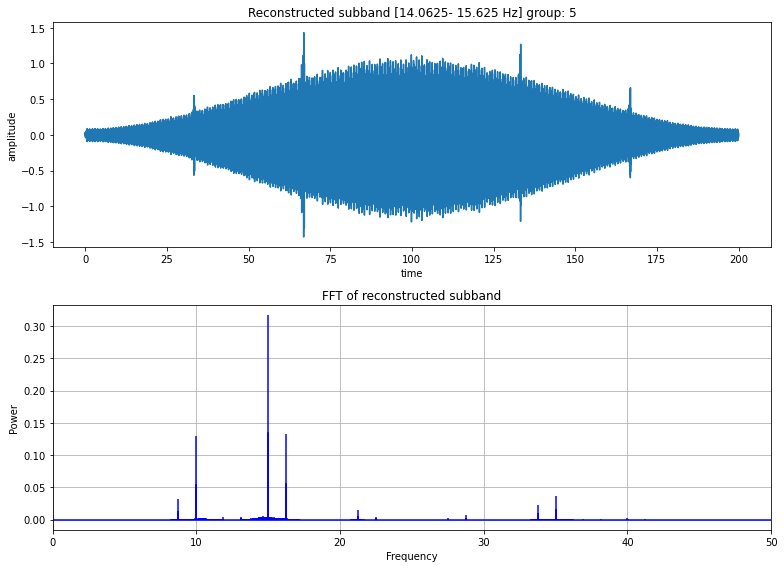

energy of recovered signal: 0.09473390213753335
kurtosis of recovered signal: 1.26754504908485
crest factor of recovered signal: 8.237741536715928

energy of node coefficients: 2.984085637098721
kurtosis of node coefficients: 2.8281038524676148
crest factor of node coefficients: -5.118631595130475


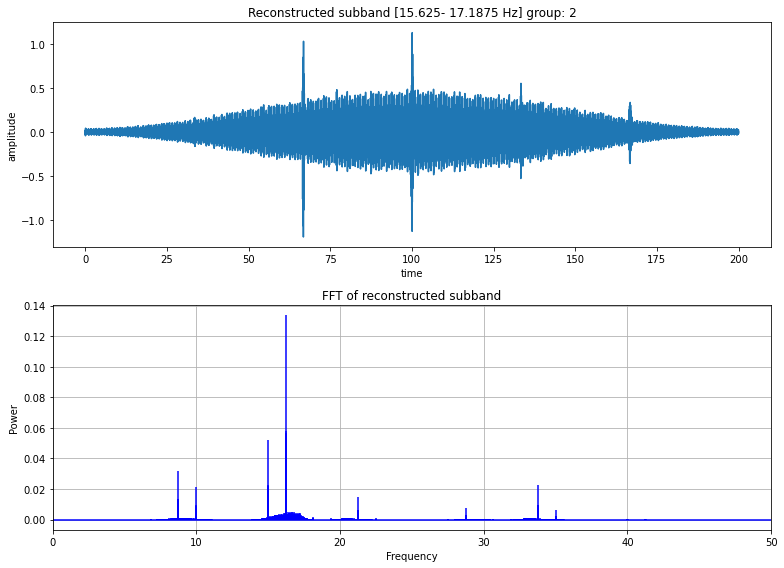

energy of recovered signal: 0.01687668471352886
kurtosis of recovered signal: 3.6391391276267164
crest factor of recovered signal: 10.398434071101219

energy of node coefficients: 0.5315727434723879
kurtosis of node coefficients: 4.798114927900948
crest factor of node coefficients: 0.6708157419616103


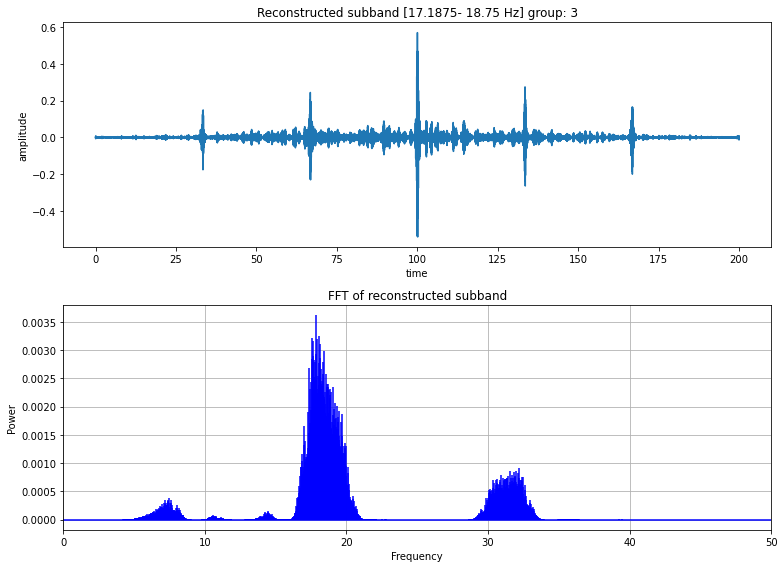

energy of recovered signal: 0.000526378278468696
kurtosis of recovered signal: 147.91957671851821
crest factor of recovered signal: 11.52225355739398

energy of node coefficients: 0.01656528998993734
kurtosis of node coefficients: 74.71597424702992
crest factor of node coefficients: 8.3814065703317


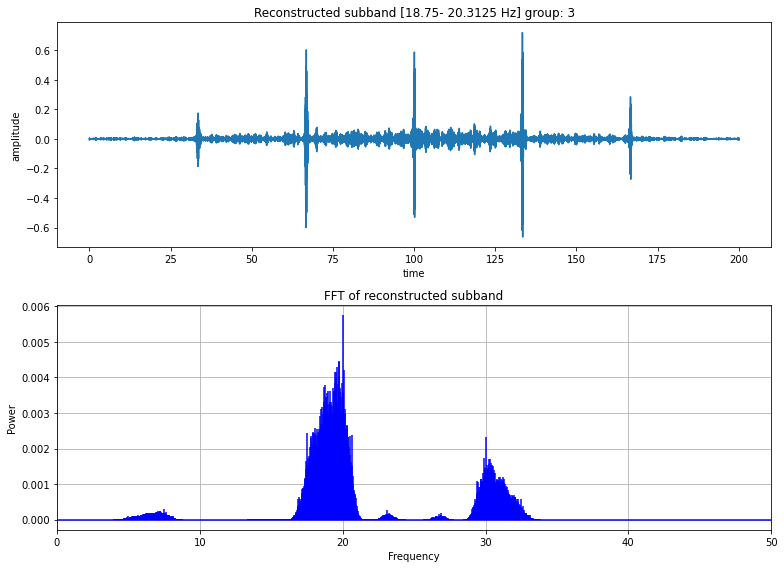

energy of recovered signal: 0.0008810955423501462
kurtosis of recovered signal: 167.54635122099836
crest factor of recovered signal: 12.408894936453219

energy of node coefficients: 0.02760567796616135
kurtosis of node coefficients: 95.9177846945914
crest factor of node coefficients: 7.97986395692576


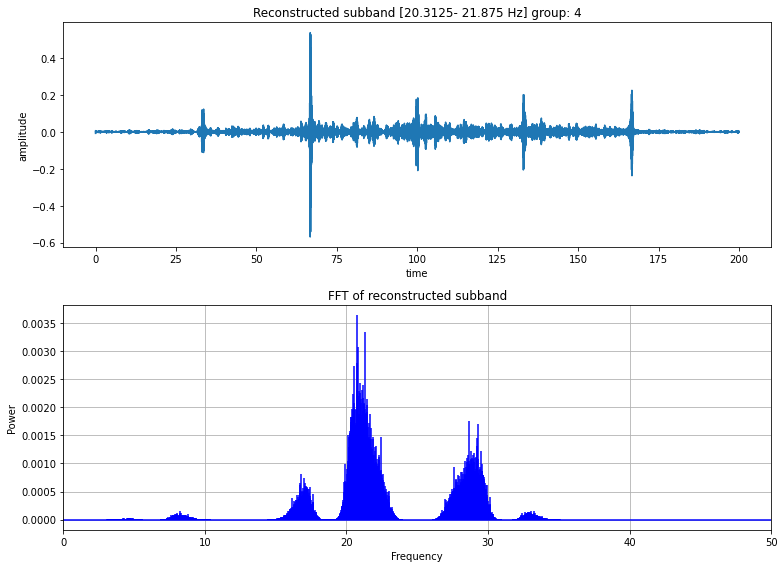

energy of recovered signal: 0.0004112367347398227
kurtosis of recovered signal: 189.93465059325578
crest factor of recovered signal: 12.037226470646956

energy of node coefficients: 0.01296201294965337
kurtosis of node coefficients: 105.5366659707656
crest factor of node coefficients: 9.920967894513383


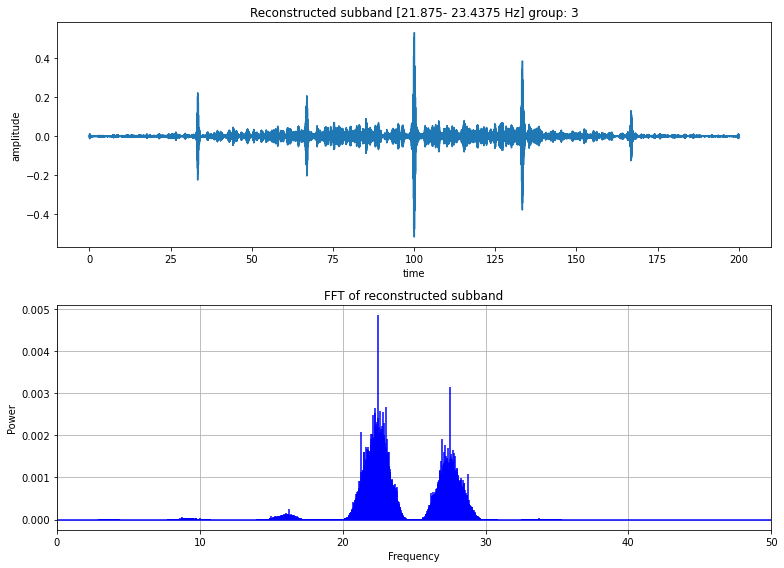

energy of recovered signal: 0.0004790464233763464
kurtosis of recovered signal: 163.3326868953842
crest factor of recovered signal: 11.121049670775871

energy of node coefficients: 0.015084426883837878
kurtosis of node coefficients: 103.03982812109352
crest factor of node coefficients: 9.48686423053536


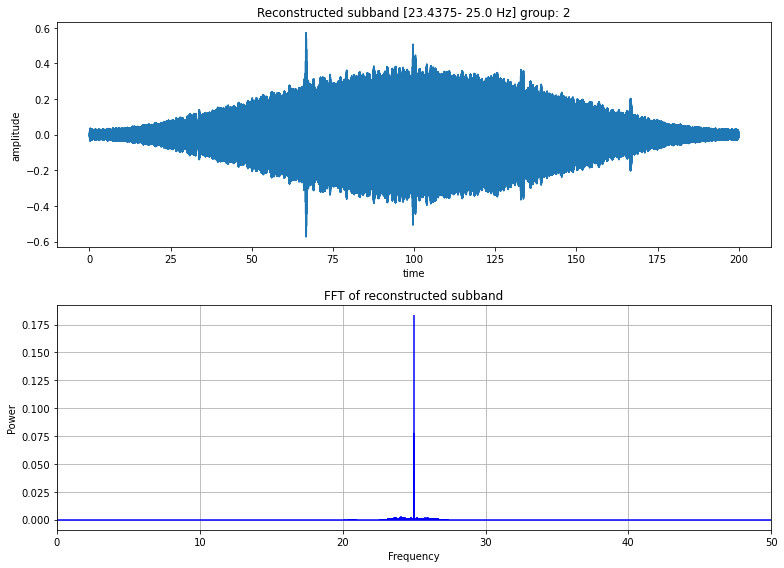

energy of recovered signal: 0.023256517316813753
kurtosis of recovered signal: 0.8023747337170501
crest factor of recovered signal: 3.3541812563822173

energy of node coefficients: 0.21018806488482844
kurtosis of node coefficients: 1.7746248479560545
crest factor of node coefficients: -6.121505351680625


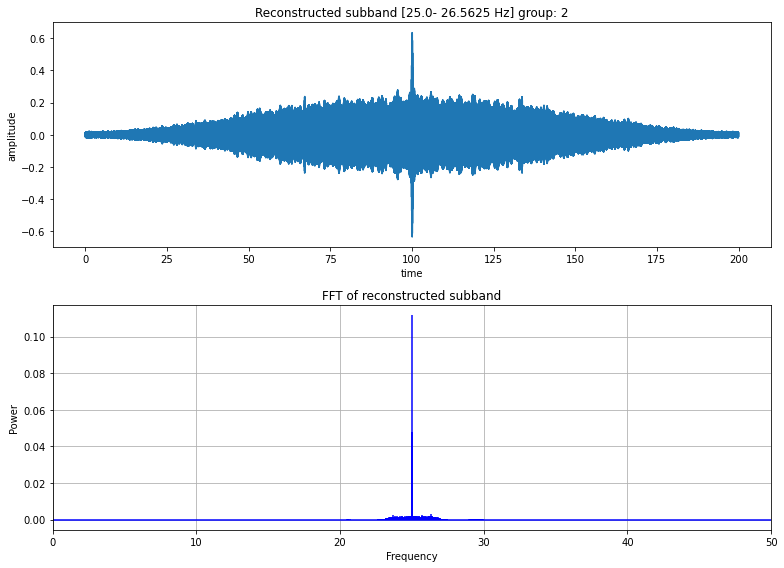

energy of recovered signal: 0.008914357378783534
kurtosis of recovered signal: 1.7517562910017936
crest factor of recovered signal: 6.309833507274477

energy of node coefficients: 0.0867020526903707
kurtosis of node coefficients: 4.190299457205855
crest factor of node coefficients: -1.2766392112338332


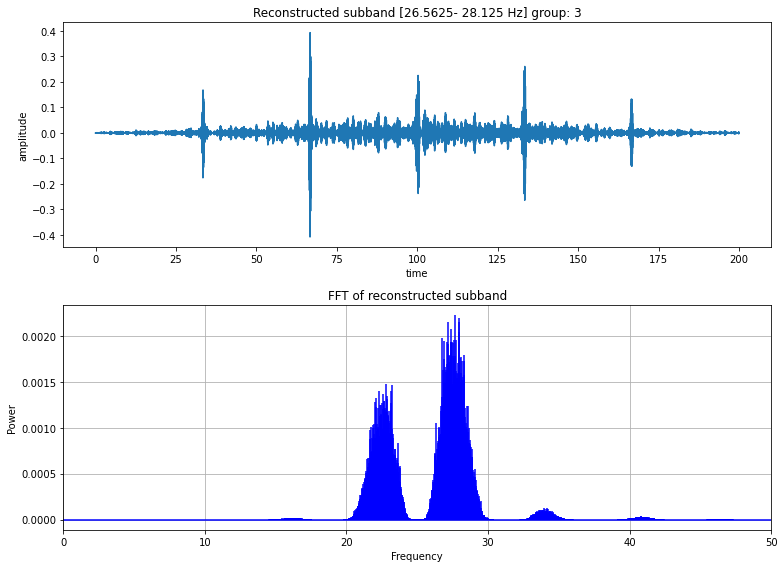

energy of recovered signal: 0.00032133831744206786
kurtosis of recovered signal: 99.25523043296688
crest factor of recovered signal: 9.670984733130162

energy of node coefficients: 0.010122523178999603
kurtosis of node coefficients: 37.95895563848565
crest factor of node coefficients: 5.976853289546197


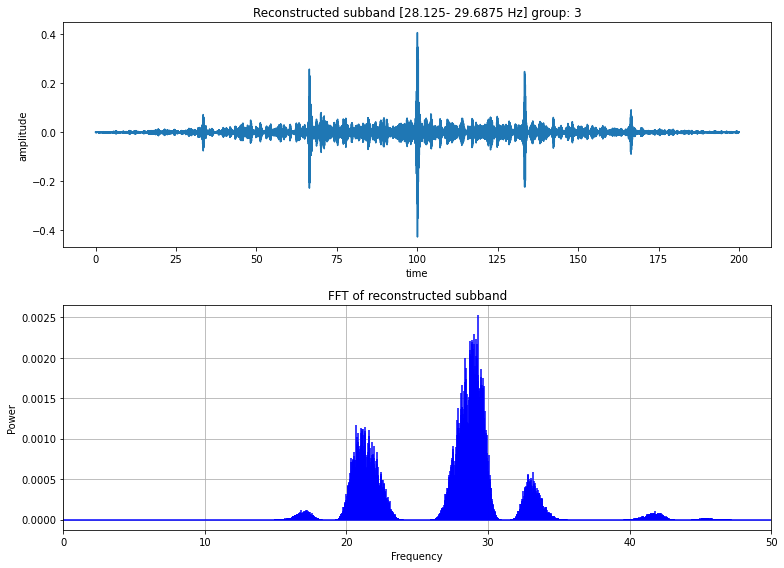

energy of recovered signal: 0.000306369605360144
kurtosis of recovered signal: 119.05533513424085
crest factor of recovered signal: 10.195549085010942

energy of node coefficients: 0.009645771516587626
kurtosis of node coefficients: 51.037794772484546
crest factor of node coefficients: 7.216034037132413


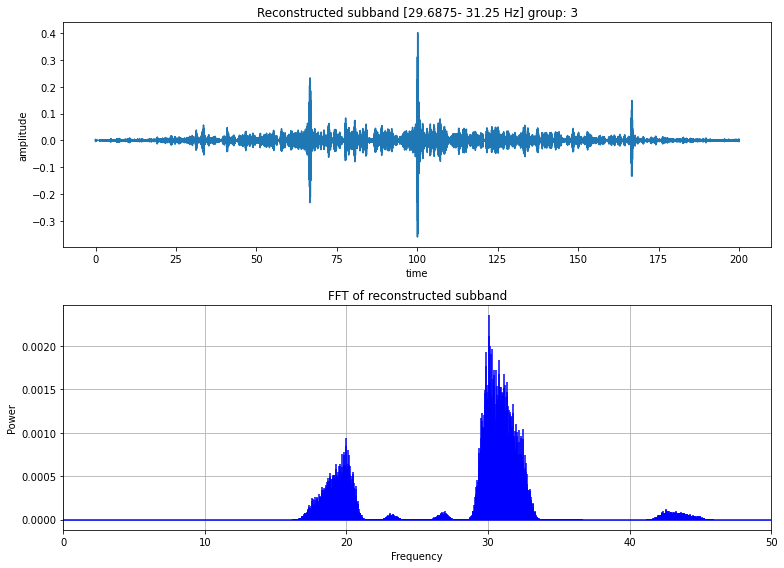

energy of recovered signal: 0.0002437226598841191
kurtosis of recovered signal: 110.83085085159402
crest factor of recovered signal: 10.15261528130183

energy of node coefficients: 0.007644320926634744
kurtosis of node coefficients: 71.22566734582853
crest factor of node coefficients: 8.94737295634907


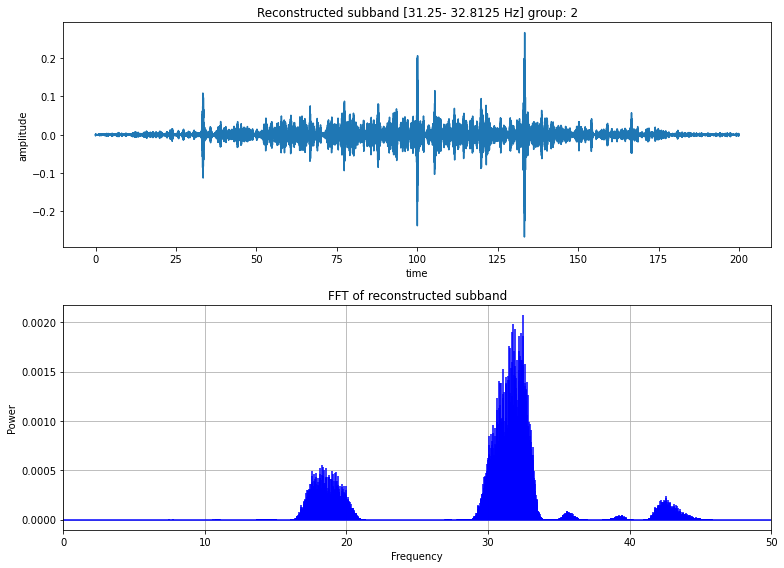

energy of recovered signal: 0.0002103006038832624
kurtosis of recovered signal: 45.881799633952475
crest factor of recovered signal: 6.92300242887356

energy of node coefficients: 0.006593270796608738
kurtosis of node coefficients: 20.97408059071514
crest factor of node coefficients: 4.477760178279989


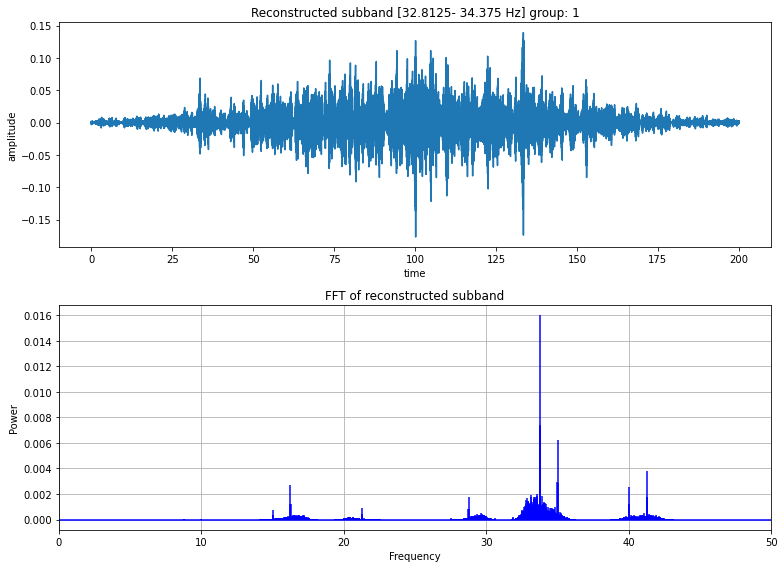

energy of recovered signal: 0.00039055324474411167
kurtosis of recovered signal: 4.903522874697538
crest factor of recovered signal: 2.001072751942767

energy of node coefficients: 0.012307278480341017
kurtosis of node coefficients: 5.905794971519722
crest factor of node coefficients: 0.8098481346433107


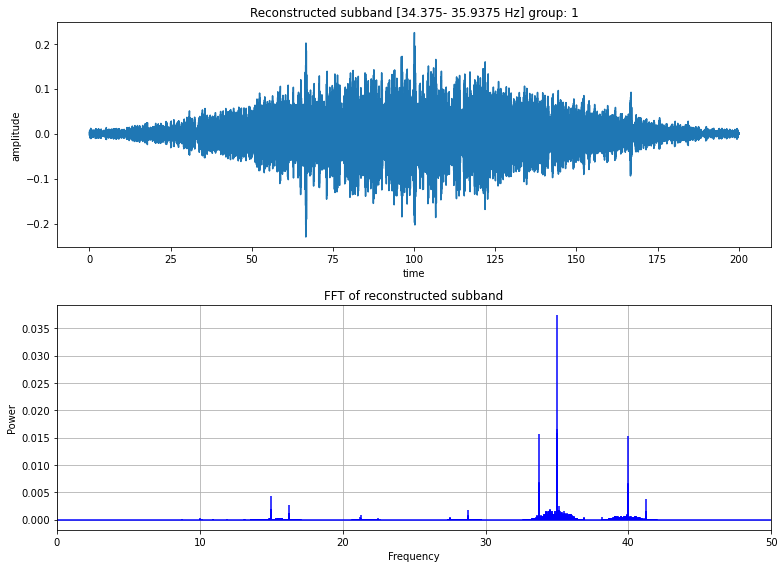

energy of recovered signal: 0.0014876542091239854
kurtosis of recovered signal: 2.12636695525961
crest factor of recovered signal: 1.371019211910973

energy of node coefficients: 0.046860590577388984
kurtosis of node coefficients: 3.8084803788767188
crest factor of node coefficients: -1.9876211164765565


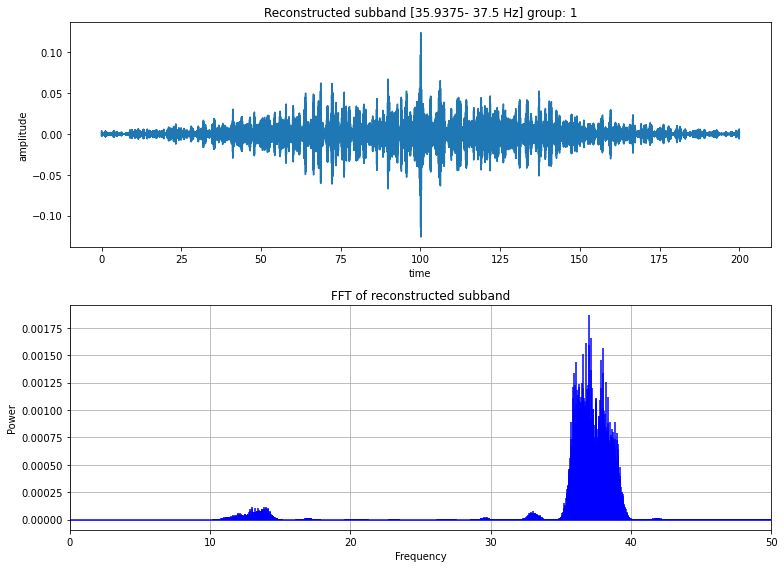

energy of recovered signal: 0.00013179596788114592
kurtosis of recovered signal: 9.469955419849356
crest factor of recovered signal: 1.4278275196714094

energy of node coefficients: 0.00415273970351583
kurtosis of node coefficients: 6.475748854281882
crest factor of node coefficients: 0.6468178731609163


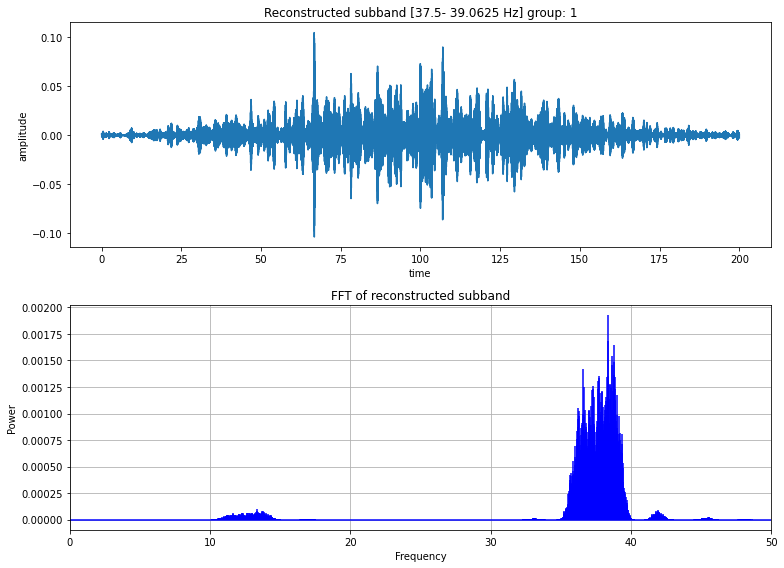

energy of recovered signal: 0.00014291533305621723
kurtosis of recovered signal: 7.201644507398921
crest factor of recovered signal: -0.3530455972231351

energy of node coefficients: 0.004499171017455626
kurtosis of node coefficients: 7.048686367616887
crest factor of node coefficients: 0.8794896876353859


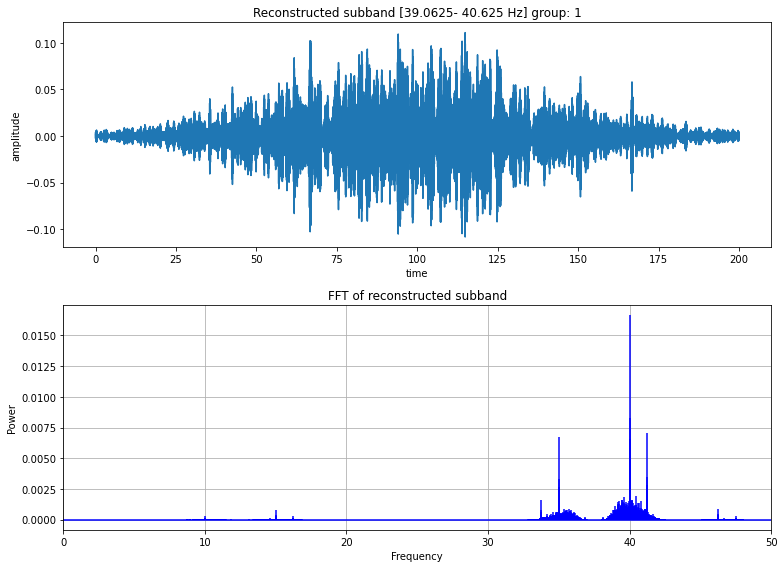

energy of recovered signal: 0.00041935230615694475
kurtosis of recovered signal: 3.2016989321051916
crest factor of recovered signal: -2.1989540492078663

energy of node coefficients: 0.01320981485581364
kurtosis of node coefficients: 4.490258942033682
crest factor of node coefficients: -2.9106934990763578


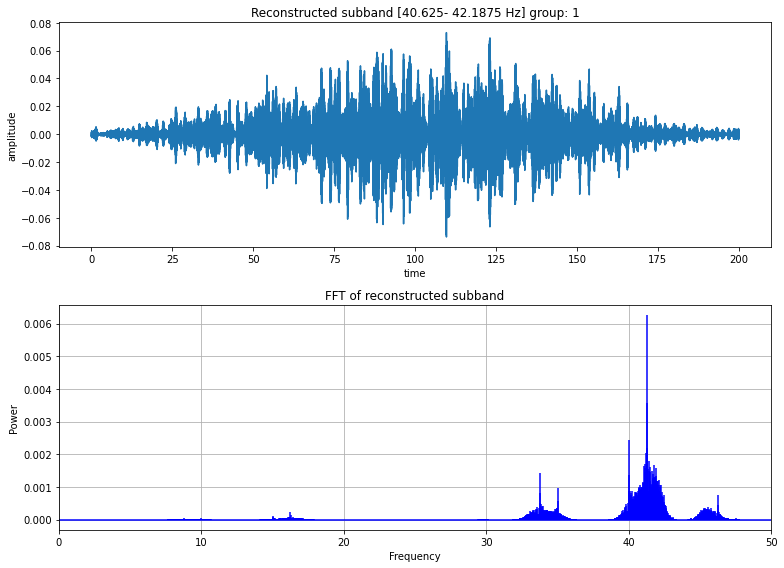

energy of recovered signal: 0.00016221918104561718
kurtosis of recovered signal: 3.516992366602844
crest factor of recovered signal: -3.694764638233776

energy of node coefficients: 0.005109967402928119
kurtosis of node coefficients: 4.978423078520247
crest factor of node coefficients: -1.3446531663485595


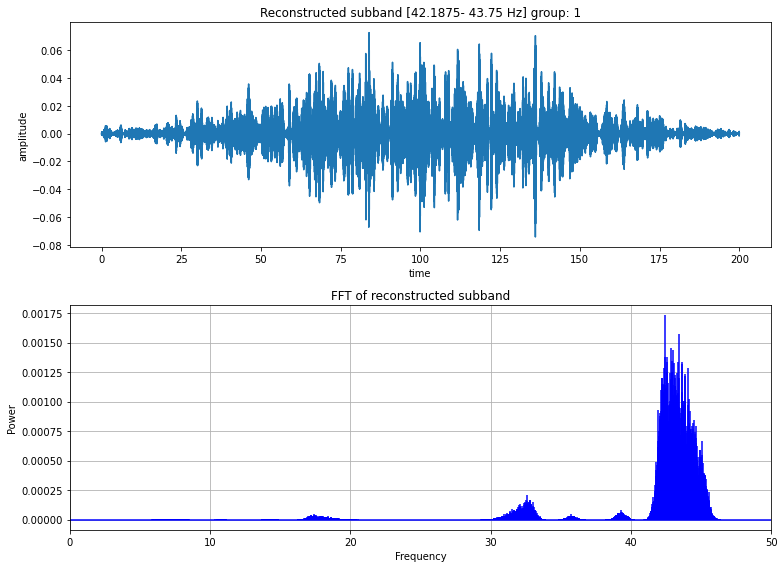

energy of recovered signal: 0.00013292731724421427
kurtosis of recovered signal: 4.415960942001209
crest factor of recovered signal: -3.214433887648406

energy of node coefficients: 0.004173608382115147
kurtosis of node coefficients: 5.203528690422979
crest factor of node coefficients: -2.1231258197113685


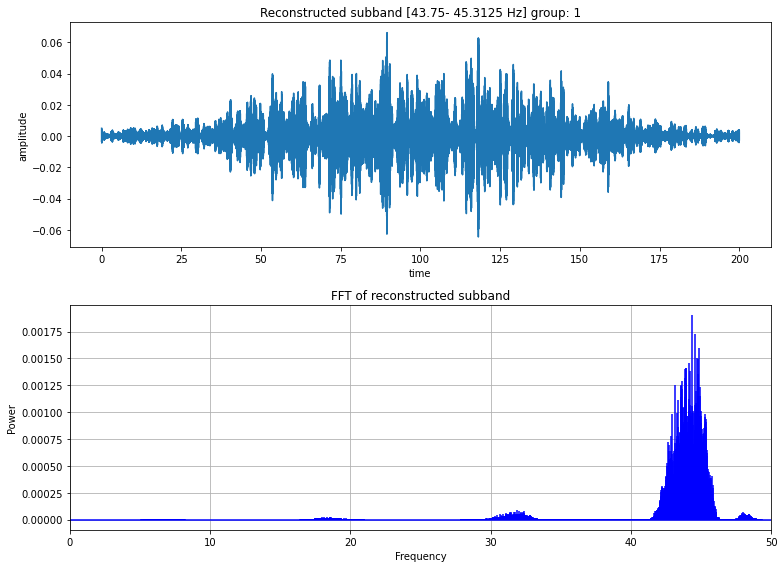

energy of recovered signal: 0.00011040074564139993
kurtosis of recovered signal: 3.8778121349120713
crest factor of recovered signal: -3.8032137171372344

energy of node coefficients: 0.003480109955803648
kurtosis of node coefficients: 5.207899871733327
crest factor of node coefficients: -0.6437800404823669


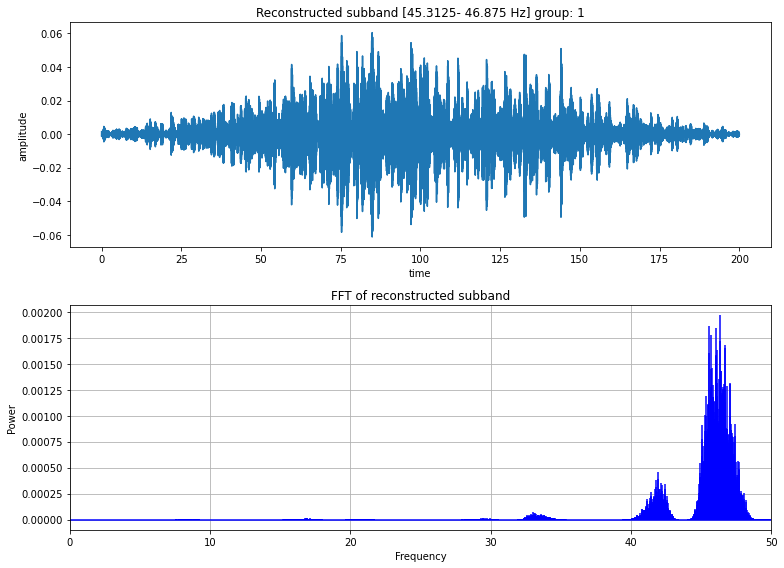

energy of recovered signal: 0.00012834495869477457
kurtosis of recovered signal: 3.121029852817575
crest factor of recovered signal: -4.791812785055297

energy of node coefficients: 0.004018349974097156
kurtosis of node coefficients: 5.108512265083664
crest factor of node coefficients: -2.0514506831243216


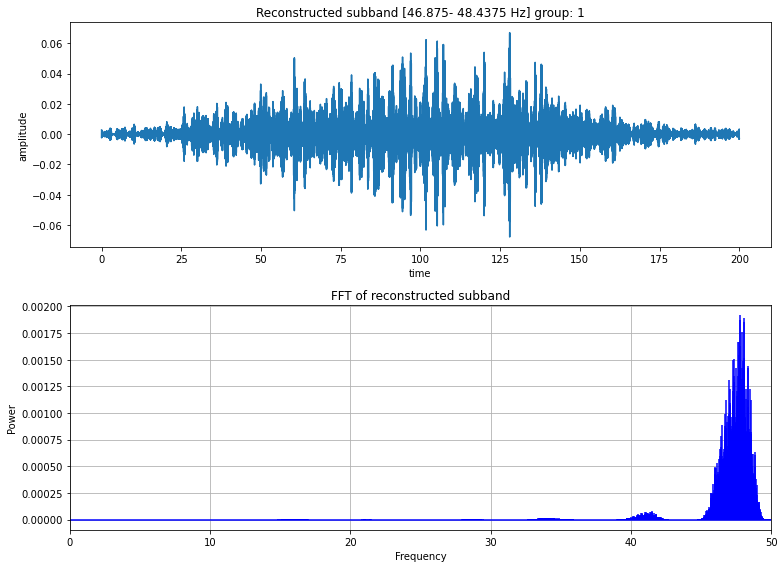

energy of recovered signal: 0.00012575521184950334
kurtosis of recovered signal: 4.086484341518859
crest factor of recovered signal: -3.8566924806618754

energy of node coefficients: 0.003958124719970207
kurtosis of node coefficients: 5.651828216558266
crest factor of node coefficients: -1.5172857376546454


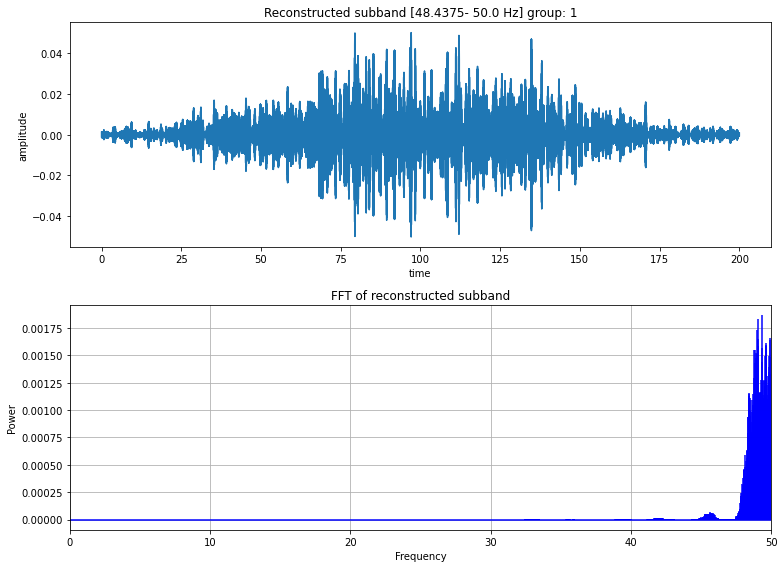

energy of recovered signal: 0.00012069926708531311
kurtosis of recovered signal: 2.6247315219996405
crest factor of recovered signal: -6.380895694141236

energy of node coefficients: 0.003803680623948174
kurtosis of node coefficients: 5.70114890771934
crest factor of node coefficients: -1.4090152562996123


array([-0.00436973,  0.02172076,  0.12938192, ..., -0.05500957,
       -0.03680896,  0.01075763])

In [35]:
plot_reconstructions(rec, group=reassigned_pca_labels)

# Appendix

### kurtosis and crest factor calculations
testing kurtosis and crest factor calculations on wavelet packet coefficients and reconstructed waves

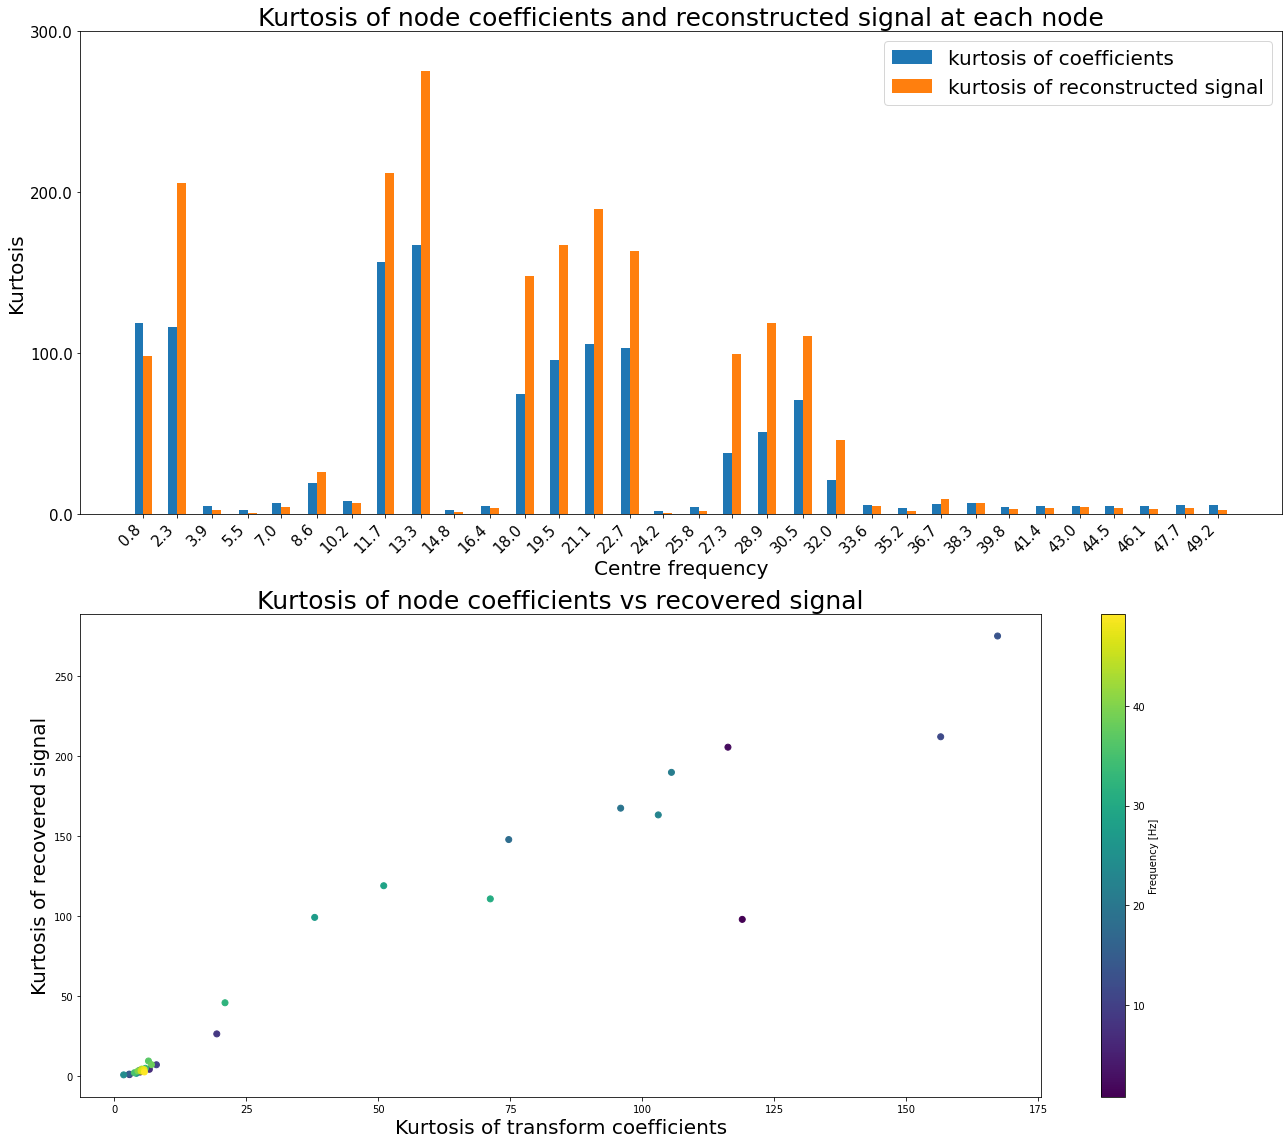

In [38]:
# gather data
cent_freqs = [
    round(1 / 2 * sum(node.frequency_range), 1)
    for node in tr_ob.get_level(order="freq")
]
cent_freqs = np.array(cent_freqs)
sparse_cent_freqs = [
    cent_freq if id % 1 == 0 else "" for id, cent_freq in enumerate(cent_freqs)
]
coef_kurtosis = [node.kurtosis for node, *_ in rec]
kurtosis = [sc.kurtosis(i) for _, i, *_ in rec]

# plot bar chart
fig, ax = plt.subplots(2)
width = 0.4

ax[0].bar(
    cent_freqs, coef_kurtosis, width, align="center", label="kurtosis of coefficients"
)
shifted_freqs = cent_freqs + width
ax[0].bar(
    shifted_freqs,
    kurtosis,
    width,
    align="center",
    label="kurtosis of reconstructed signal",
)

# set the x-axis tick positions and labels
ax[0].set_xticks(cent_freqs + width / 2)
ax[0].set_xticklabels(sparse_cent_freqs, rotation=45, ha="right", fontsize=15)
ax[0].set_yticks(ax[0].get_yticks())
ax[0].set_yticklabels(ax[0].get_yticks(), fontsize=15)

ax[0].set_title(
    "Kurtosis of node coefficients and reconstructed signal at each node", fontsize=25
)
ax[0].set_xlabel("Centre frequency", fontsize=20)
ax[0].set_ylabel("Kurtosis", fontsize=20)
ax[0].legend(fontsize=20)

fig.set_size_inches(18, 16)

scatter = ax[1].scatter(coef_kurtosis, kurtosis, c=cent_freqs)
ax[1].set_title("Kurtosis of node coefficients vs recovered signal", fontsize=25)
ax[1].set_xlabel("Kurtosis of transform coefficients", fontsize=20)
ax[1].set_ylabel("Kurtosis of recovered signal", fontsize=20)

fig.colorbar(scatter, ax=ax[1], label="Frequency [Hz]")

fig.tight_layout()
plt.show()

(<wavelet_transform.wpt.transform_node.Node object at 0x0000016038E48700>, array([0.03891802, 0.03772029, 0.03647476, ..., 0.00171628, 0.00178715,
       0.00184347]), array([ 7.43467406e-03+0.00000000e+00j, -1.44125197e-03+7.62249998e-04j,
       -2.03911715e-03-8.05120117e-04j, ...,
        1.88173003e-06-8.72725079e-10j,  1.88173003e-06-5.81816695e-10j,
        1.88173002e-06-2.90908341e-10j]), 0.002158620232143051, 98.00946152926531, 9.7167333813432)


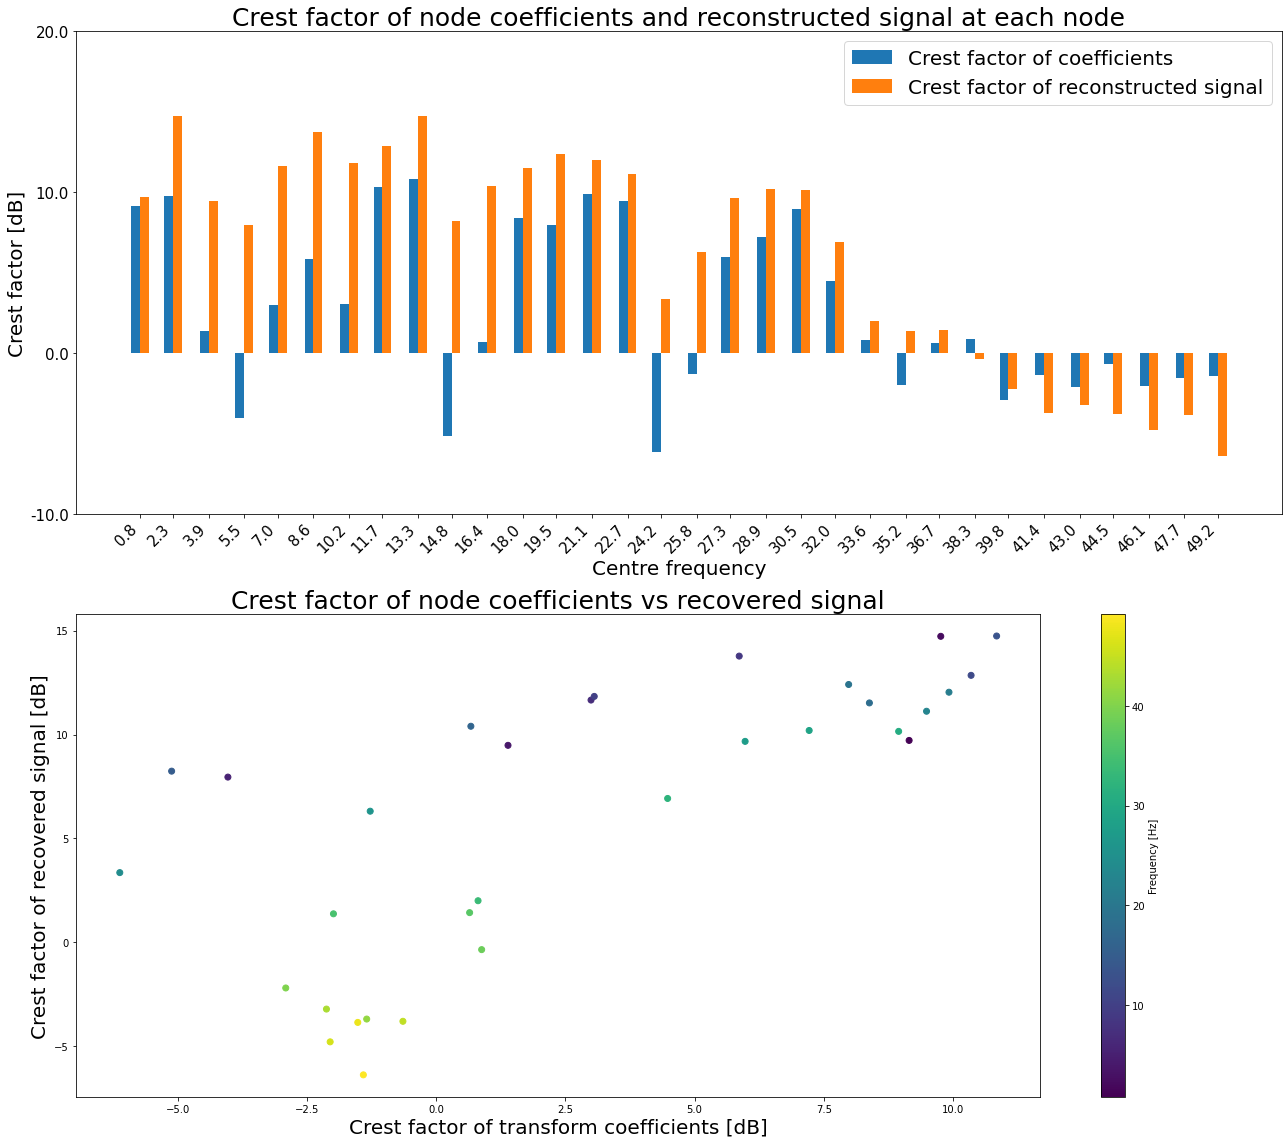

In [43]:
# gather data
print(rec[0])
coef_crest = [node.crest_factor for node, *_ in rec]
crest = [calc_crest_factor(i) for _, i, *_ in rec]

# plot bar chart
fig, ax = plt.subplots(2)
width = 0.4

ax[0].bar(
    cent_freqs, coef_crest, width, align="center", label="Crest factor of coefficients"
)
shifted_freqs = cent_freqs + width
ax[0].bar(
    shifted_freqs,
    crest,
    width,
    align="center",
    label="Crest factor of reconstructed signal",
)

# set the x-axis tick positions and labels
ax[0].set_xticks(cent_freqs + width / 2)
ax[0].set_xticklabels(sparse_cent_freqs, rotation=45, ha="right", fontsize=15)
ax[0].set_yticks(ax[0].get_yticks())
ax[0].set_yticklabels(ax[0].get_yticks(), fontsize=15)

ax[0].set_title(
    "Crest factor of node coefficients and reconstructed signal at each node",
    fontsize=25,
)
ax[0].set_xlabel("Centre frequency", fontsize=20)
ax[0].set_ylabel("Crest factor [dB]", fontsize=20)
ax[0].legend(fontsize=20)

fig.set_size_inches(18, 16)

scatter = ax[1].scatter(coef_crest, crest, c=cent_freqs)
ax[1].set_title("Crest factor of node coefficients vs recovered signal", fontsize=25)
ax[1].set_xlabel("Crest factor of transform coefficients [dB]", fontsize=20)
ax[1].set_ylabel("Crest factor of recovered signal [dB]", fontsize=20)

fig.colorbar(scatter, ax=ax[1], label="Frequency [Hz]")

fig.tight_layout()
plt.show()

### plot of reconstruction

In [ ]:
# plot sum of highest energy subbands
plt.figure(figsize=(11, 4))
plt.plot(t_plot, partial_rec)
plt.xlabel("time [s]")
plt.ylabel("amplitude [DL]")
plt.title(
    f"sum of {n_highest} highest [{sort_by}] reconstructions vs full reconstruction"
)

# plot full reconstruction
full_rec = inv.inv_dwpt(tr_ob, wavelet)
plt.plot(t_plot, full_rec[:signal_length], "--r")
plt.plot(t_plot, data, ":k")
plt.legend(["selective reconstruction", "full reconstruction", "data"], loc="best")
plt.show()

### testing frequency sorting algorithm

In [ ]:
my_frequencies = [node.path for node in tr_ob.get_level(order="freq")]
pywt_nodes = pywt._wavelet_packets.get_graycode_order(levels)
print("my nodes ordered by frequency:", my_frequencies)
print("pywt order:                   ", pywt_nodes)
print(my_frequencies == pywt_nodes)